<p style="color: #00897B; font-weight: 700; letter-spacing: 0.12em;">ONLINE LEARNING · COURSE COMPANION</p>

# Online learning, one day at a time

**FTL · FTRL · OGD | Squared loss**

One product, one store, one forecast each morning. We learn a single demand level so that every update stays easy to read beside the slides.

1. Generate a small demand series.
2. Predict days $T+1, T+2, \ldots$, revealing one observation at a time.
3. Compare forecasts and average regret for three update rules.

These are **rolling one-step-ahead forecasts**, not a whole future trajectory predicted at day $T$.

Run the cells from top to bottom. The notebook needs only **NumPy** and **Matplotlib**, with no download or external data.

If needed, run `%pip install numpy matplotlib` in a new cell. The figures use a general-purpose teaching palette. Set `DARK_MODE = True` below for dark figures.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

PALETTE = {
    "teal": "#00897B",
    "skyblue": "#81D4FA",
    "blue": "#42A5F5",
    "darkblue": "#283593",
    "orange": "#FB8C00",
    "purple": "#8E24AA",
}
DARK_MODE = False
BACKGROUND = "#10212A" if DARK_MODE else "#FFFFFF"
TEXT = "#EAF5F8" if DARK_MODE else "#20343B"
GRID = "#38505C" if DARK_MODE else "#DAE6EB"

plt.rcParams.update({
    "figure.facecolor": BACKGROUND,
    "axes.facecolor": BACKGROUND,
    "text.color": TEXT,
    "axes.labelcolor": TEXT,
    "axes.edgecolor": GRID,
    "axes.titlecolor": PALETTE["skyblue"] if DARK_MODE else PALETTE["teal"],
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": TEXT,
    "ytick.color": TEXT,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.alpha": 0.5,
    "axes.axisbelow": True,
    "font.size": 11,
    "legend.frameon": False,
    "figure.dpi": 120,
})

## 1. A small, slightly realistic demand series

Daily demand has a weekly pattern, a gentle upward trend, occasional promotions and persistent noise. Values are rounded to whole units and kept between 0 and 200.

The first $T=28$ days are the **initial history**. Online evaluation starts on day $T+1$.

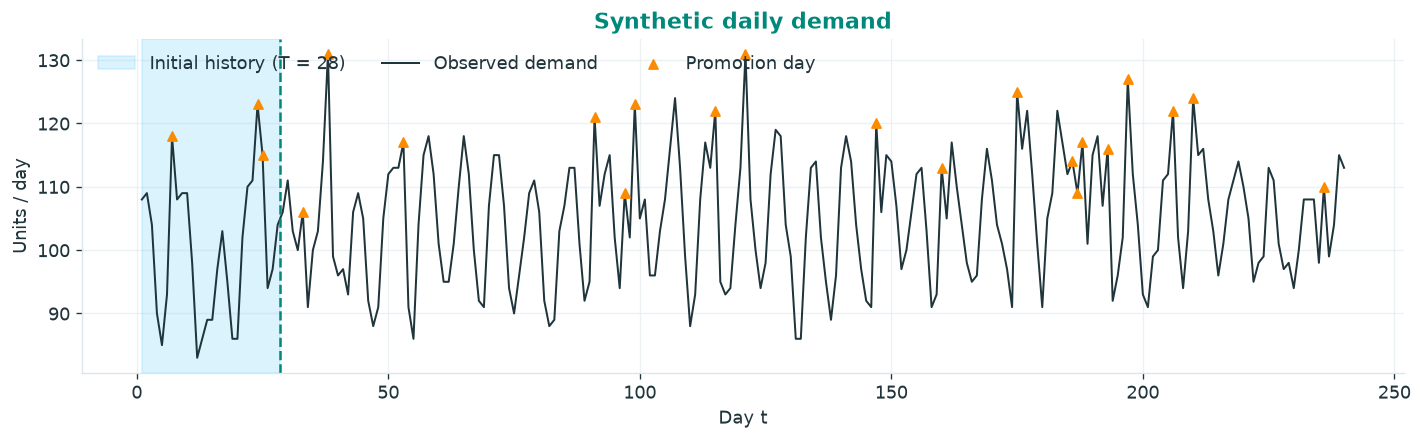

In [2]:
SEED = 7  # Fix the random draws so everyone gets the same dataset.
TOTAL_DAYS = 240  # Total simulated days, including the initial history.
T = 28  # Days observed before the first online prediction.
PROMOTION_EFFECT = 18  # Extra demand units on a promotion day.
DAILY_TREND = 0.03  # Daily increase in baseline demand, in units per day.
LOWER, UPPER = 0.0, 200.0  # Demand limits and feasible forecast interval K.

rng = np.random.default_rng(SEED)
days = np.arange(1, TOTAL_DAYS + 1)
promotion = rng.random(TOTAL_DAYS) < 0.08
noise = np.zeros(TOTAL_DAYS)
for i in range(1, TOTAL_DAYS):
    noise[i] = 0.55 * noise[i - 1] + rng.normal(0, 4)

demand = np.clip(np.rint(
    100 + DAILY_TREND * days
    + 10 * np.sin(2 * np.pi * days / 7)
    + PROMOTION_EFFECT * promotion + noise
), LOWER, UPPER)

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.axvspan(1, T + 0.5, color=PALETTE["skyblue"], alpha=0.28,
           label=f"Initial history (T = {T})")
ax.plot(days, demand, color=TEXT, linewidth=1.2, label="Observed demand")
ax.scatter(days[promotion], demand[promotion], marker="^", s=30,
           color=PALETTE["orange"], label="Promotion day", zorder=3)
ax.axvline(T + 0.5, color=PALETTE["teal"], linestyle="--")
ax.set(title="Synthetic daily demand", xlabel="Day t", ylabel="Units / day")
ax.legend(ncol=3, loc="upper left")
fig.tight_layout()
plt.show()

## 2. The same model, loss and benchmark for everyone

We deliberately learn only a level:

$$
\widehat y_t = \theta_t, \qquad \theta_t \in K=[0,200],
\qquad \ell_t(\theta)=\frac12(\theta-y_t)^2.
$$

The factor $1/2$ makes the gradient simply $\theta-y_t$. This model does **not** use the calendar or promotions as features. It will not anticipate each weekly peak.

At each day $t=T+1,T+2,\ldots$:

1. **Predict** using only observations through day $t-1$.
2. **Observe** $y_t$ and incur the squared loss.
3. **Update** the level for the next day.

All methods use the same initial history. Only the later days count toward reported loss and regret. Generating the whole series in advance is just a simulation convenience.

In [3]:
history = demand[:T]
online_y = demand[T:]
online_days = days[T:]
n = np.arange(1, len(online_y) + 1)
results = {}

### What does “regret / time” mean?

After $n$ online predictions, compare with the **best single fixed level** on those same $n$ days:

$$
R_n = \sum_{j=1}^{n}\frac12
\left(\widehat y_{T+j}-y_{T+j}\right)^2
- \min_{u\in K}\sum_{j=1}^{n}\frac12(u-y_{T+j})^2.
$$

The right-hand plot will show **average regret $R_n/n$** against calendar day $t=T+n$. This is excess loss per online day, not computation time.

For squared loss, the best fixed level is the clipped mean of the $n$ online observations. We compute its total loss using sums and sums of squares. At each plotted horizon $n$, **one fixed level is applied to all $n$ observations**. This is not the loss of a changing running-mean oracle.

The benchmark uses hindsight only for evaluation. No learner can access it. The initial history is excluded from both sides of the regret calculation.

In [4]:
prefix_sum = np.cumsum(online_y)  # For each n: sum of the first n online demands.
prefix_sum_sq = np.cumsum(online_y ** 2)  # Sum of squared demands for each prefix.
best_fixed_level = np.clip(prefix_sum / n, LOWER, UPPER)  # Best feasible constant per prefix.
# Expand sum((y - u)**2) as sum(y**2) - 2*u*sum(y) + n*u**2.
best_fixed_loss = 0.5 * (  # Apply each prefix's fixed level to all days in that prefix.
    prefix_sum_sq - 2 * best_fixed_level * prefix_sum
    + n * best_fixed_level ** 2
)

The next helper only evaluates and plots saved forecasts. The learning rules remain in their own sections.

In [5]:
def show_result(name, prediction, color, linestyle):
    """Evaluate forecasts and plot predictions and average regret.

    prediction contains one forecast per online day, in chronological order.
    name labels the method; color and linestyle control its curves.
    Uses the shared benchmark and stores losses and regret in results.
    """
    loss = 0.5 * (prediction - online_y) ** 2
    regret = np.cumsum(loss) - best_fixed_loss
    results[name] = dict(prediction=prediction, loss=loss, regret=regret,
                         color=color, linestyle=linestyle)

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    axes[0].plot(online_days, online_y, color=TEXT, alpha=0.45,
                 linewidth=1, label="Observed demand")
    axes[0].plot(online_days, prediction, color=color, linestyle=linestyle,
                 linewidth=2.3, label=f"{name} forecast")
    axes[0].set(title=f"{name}: one-step-ahead forecasts",
                xlabel="Day t", ylabel="Units / day")
    axes[0].legend(loc="upper left")

    axes[1].axhline(0, color=TEXT, linewidth=1, linestyle=":", alpha=0.6)
    axes[1].plot(online_days, regret / n, color=color,
                 linestyle=linestyle, linewidth=2.3)
    axes[1].set(title=f"{name}: average regret",
                xlabel="Day t (n = t - T online predictions)",
                ylabel=r"$R_n / n$ (squared units)")
    fig.tight_layout()
    plt.show()

## 3. Follow the Leader (FTL)

Use the level that best fits **all observations seen so far**, including the initial history:

$$
\theta_{t+1}
=\arg\min_{u\in K}\sum_{s=1}^{t}\frac12(u-y_s)^2
=\Pi_K\!\left(\frac{\sum_{s=1}^{t}y_s}{t}\right).
$$

Here $\Pi_K(z)=\operatorname{clip}(z,0,200)$. We only need a running sum and a count. As the history grows, one new observation has less influence.

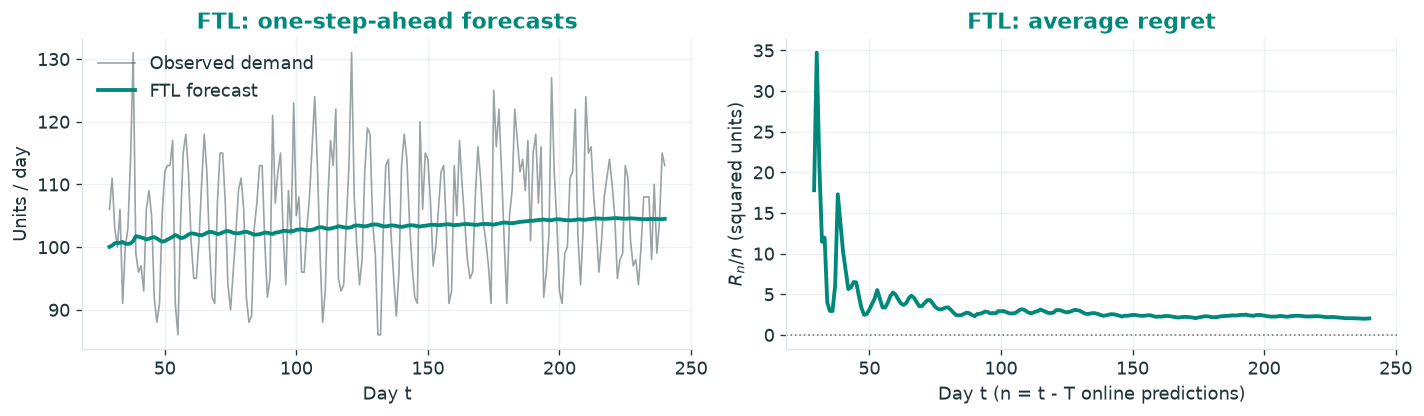

In [6]:
ftl = np.empty(len(online_y))
total = float(history.sum())
count = T

for k in range(len(online_y)):
    ftl[k] = np.clip(total / count, LOWER, UPPER)

    # Reveal today's demand only after storing today's prediction.
    observed = online_y[k]
    total += observed
    count += 1

show_result("FTL", ftl, PALETTE["teal"], "-")

## 4. Follow the Regularized Leader (FTRL)

Add a quadratic penalty around a prior level $\theta_0=90$:

$$
\theta_{t+1}
=\arg\min_{u\in K}\left\{
\sum_{s=1}^{t}\frac12(u-y_s)^2
+\frac{\lambda}{2}(u-\theta_0)^2\right\}
=\Pi_K\!\left(\frac{\sum_{s=1}^{t}y_s+\lambda\theta_0}{t+\lambda}\right).
$$

We choose $\lambda=20$ before the online period. This acts like **20 extra observations at the prior level**. A stronger penalty means a stronger pull toward that prior, which need not be correct.

This is FTRL on the **full squared losses**, not linearized FTRL. The penalty has a fixed weight in the cumulative objective. It helps choose the forecasts but is **not added to the evaluated loss or regret**.

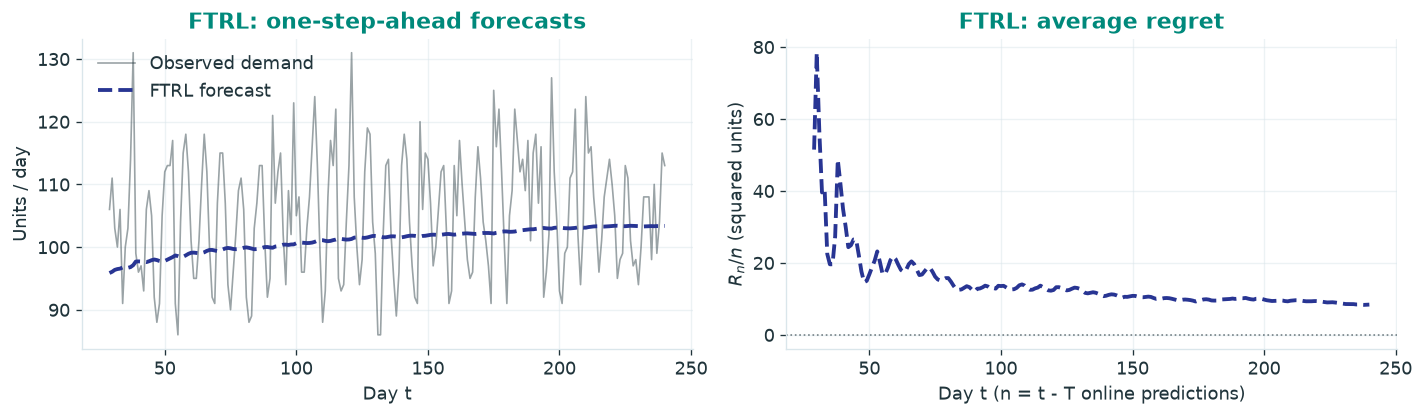

In [7]:
LAMBDA = 20.0  # Prior weight, equivalent to 20 pseudo-observations.
PRIOR = 90.0  # Demand level favored by the regularizer, in units per day.
ftrl = np.empty(len(online_y))  # One saved forecast for each online day.
total = float(history.sum())  # Sum of demands observed before online evaluation.
count = T  # Number of demand observations already available.

for k in range(len(online_y)):
    ftrl[k] = np.clip((total + LAMBDA * PRIOR) / (count + LAMBDA), LOWER, UPPER)

    observed = online_y[k]
    total += observed
    count += 1

show_result("FTRL", ftrl, PALETTE["darkblue"], "--")

## 5. Online Gradient Descent (OGD)

Start at the mean of the initial history. After each new observation, take one gradient step:

$$
g_t=\theta_t-y_t, \qquad
\theta_{t+1}=\Pi_K(\theta_t-\eta_n g_t),
\qquad \eta_n=\frac{0.3}{\sqrt n},\quad n=t-T.
$$

An underprediction gives a negative gradient, so the next level goes up. An overprediction makes it go down. The decreasing step size makes later corrections smaller.

This schedule is fixed in advance and illustrates OGD. It is not tuned to win this example. The plots below are an experiment, not a proof of a regret rate.

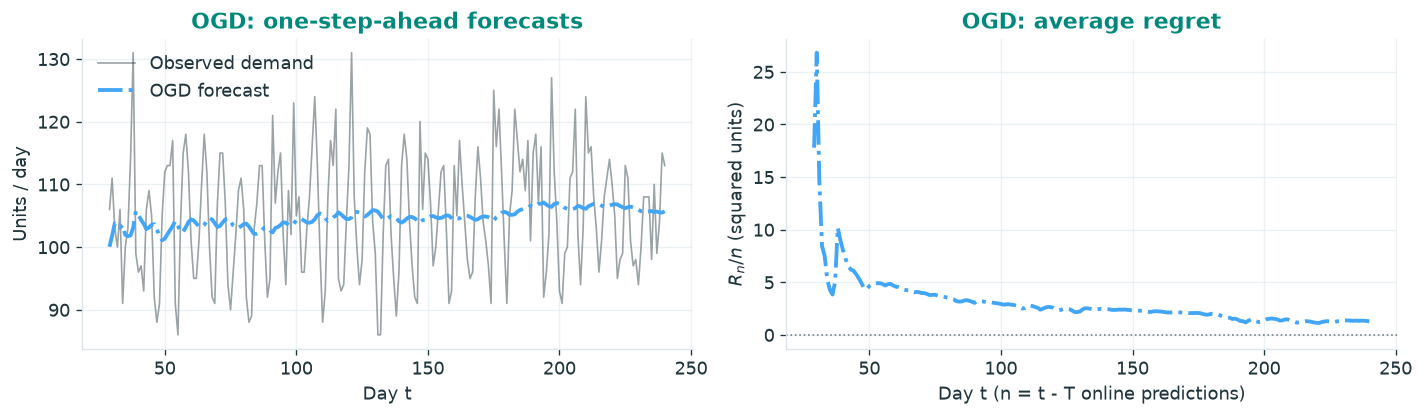

In [8]:
ETA0 = 0.3  # Initial step size; later steps use ETA0 / sqrt(n).
ogd = np.empty(len(online_y))  # One saved forecast for each online day.
theta = float(np.clip(history.mean(), LOWER, UPPER))  # Start at the historical mean, projected onto K.

for k in range(len(online_y)):
    ogd[k] = theta

    observed = online_y[k]
    gradient = theta - observed
    eta = ETA0 / np.sqrt(k + 1)
    theta = float(np.clip(theta - eta * gradient, LOWER, UPPER))

show_result("OGD", ogd, PALETTE["blue"], "-.")

## 6. Compare on exactly the same days

Each curve uses the same loss, feasible set and hindsight benchmark. Lower average regret is better **relative to that benchmark**. It is not the same quantity as prediction loss.

Regret can be negative: an adapting sequence of levels can beat the best fixed level. A small average regret does not mean every forecast is accurate, and a finite plot does not establish an asymptotic guarantee.

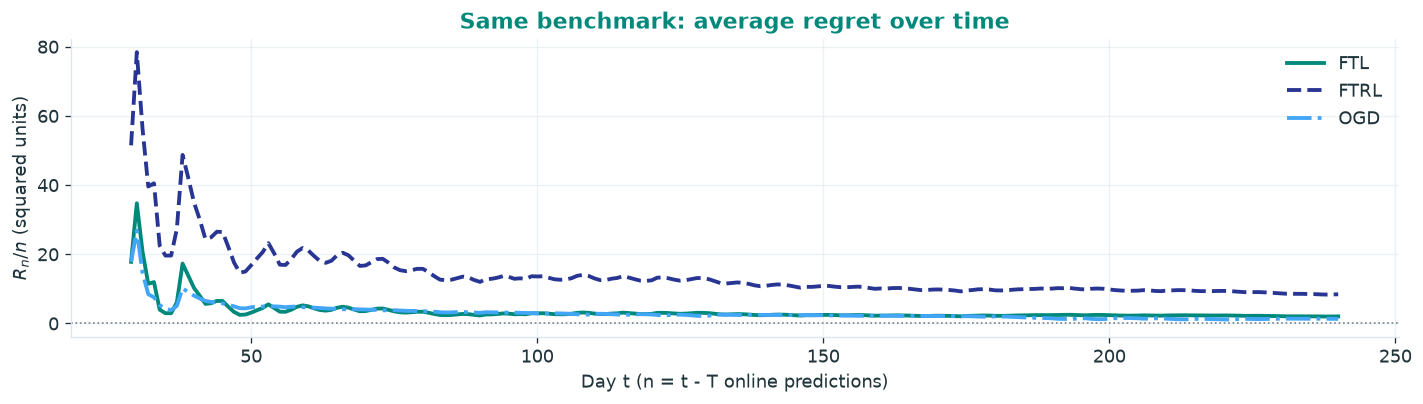

Online evaluation: days 29 to 240 (212 predictions)
Method     Mean squared loss    Final regret    Final regret / n
FTL                    48.83          427.45                2.02
FTRL                   55.21         1781.30                8.40
OGD                    48.10          272.55                1.29


In [9]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.axhline(0, color=TEXT, linewidth=1, linestyle=":", alpha=0.6)
for name, result in results.items():
    ax.plot(online_days, result["regret"] / n, label=name,
            color=result["color"], linestyle=result["linestyle"], linewidth=2.3)
ax.set(title="Same benchmark: average regret over time",
       xlabel="Day t (n = t - T online predictions)",
       ylabel=r"$R_n / n$ (squared units)")
ax.legend()
fig.tight_layout()
plt.show()

print(f"Online evaluation: days {T + 1} to {TOTAL_DAYS} ({len(online_y)} predictions)")
print(f"{'Method':<8} {'Mean squared loss':>19} {'Final regret':>15} {'Final regret / n':>19}")
for name, result in results.items():
    print(f"{name:<8} {result['loss'].mean():>19.2f} "
          f"{result['regret'][-1]:>15.2f} {result['regret'][-1] / n[-1]:>19.2f}")

### Three small experiments

Change one thing, then rerun the notebook.

1. Set `LAMBDA = 0`. FTRL should become identical to FTL.
2. Try `ETA0 = 0.05`, then `ETA0 = 0.8`. Compare responsiveness and average regret.
3. In OGD, replace the step-size line with `eta = 1 / (T + k + 1)`. Starting from the historical mean, this update is exactly the running average, so OGD and FTL coincide here.

**Keep in mind:** we learned a level, not the weekly pattern or promotion effect. Adding those as features would change the prediction model, while keeping the predict, observe, update protocol.